<a href="https://colab.research.google.com/github/ushkgowda/Multi-Domain-Data-Analysis-Portfolio-5-Real--Projects/blob/main/project3_weather_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Weather Data Analysis
**Portfolio: Multi-Domain Data Analysis** | Domain: Weather

**Goals:** temperature trend analysis, seasonal patterns, rainfall distribution and extreme weather events.

**Data:** the public `seattle-weather` dataset (vega-datasets): 1,461 daily records, 2012-01-01 to 2015-12-31. Units are not stated in the file; values are consistent with °C and mm, and wind is assumed to be m/s.

**Important limits:** one location and four years. Trend results describe this window only and are not climate-change evidence.

## 1. Setup and loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

raw = pd.read_csv("/content/seattle_weather (1).csv", parse_dates=["date"])
print("Shape:", raw.shape); raw.head()

Shape: (1461, 6)


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## 2. Data validation

In [2]:
full = pd.date_range(raw.date.min(), raw.date.max())
print("Missing values:", int(raw.isnull().sum().sum()), "| duplicate dates:", int(raw.date.duplicated().sum()))
print("Days present vs expected:", raw.date.nunique(), "/", len(full))
print("Min temp > max temp:", int((raw.temp_min > raw.temp_max).sum()), "| negative precip/wind:", int((raw.precipitation < 0).sum() + (raw.wind < 0).sum()))
print("Temperature range: %.1f to %.1f" % (raw.temp_min.min(), raw.temp_max.max()))
for c in ["precipitation", "temp_max", "temp_min", "wind"]:
    a, b = raw[c].quantile([.25, .75]); i = b - a
    print(f"IQR outliers in {c}:", int(((raw[c] < a - 1.5 * i) | (raw[c] > b + 1.5 * i)).sum()))
print("\nWeather label vs measured rain:")
print("  sun/fog/drizzle days with 0 mm:", int((raw.weather.isin(["sun", "fog", "drizzle"]) & (raw.precipitation == 0)).sum()), "of", int(raw.weather.isin(["sun", "fog", "drizzle"]).sum()))
print("  'rain' days with 0 mm:", int(((raw.weather == "rain") & (raw.precipitation == 0)).sum()))
print("  'snow' days with max temp > 5:", int(((raw.weather == "snow") & (raw.temp_max > 5)).sum()))

Missing values: 0 | duplicate dates: 0
Days present vs expected: 1461 / 1461
Min temp > max temp: 0 | negative precip/wind: 0
Temperature range: -7.1 to 35.6
IQR outliers in precipitation: 206
IQR outliers in temp_max: 0
IQR outliers in temp_min: 0
IQR outliers in wind: 34

Weather label vs measured rain:
  sun/fog/drizzle days with 0 mm: 794 of 794
  'rain' days with 0 mm: 44
  'snow' days with max temp > 5: 14


The measurements are complete and consistent. The weather **label** does not always match the measurements, so rainfall analysis uses measured precipitation (wet day = 1 mm or more) and the label is used only for the weather-mix chart. Outliers in precipitation are genuine heavy rain and are kept.

In [3]:
SEAS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
df = raw.sort_values("date").reset_index(drop=True)
df["Year"], df["Month"] = df.date.dt.year, df.date.dt.month
df["Season"] = pd.Categorical(df.Month.map(SEAS), ["Winter", "Spring", "Summer", "Autumn"], ordered=True)
df["temp_mean"] = (df.temp_max + df.temp_min) / 2
df["temp_range"] = df.temp_max - df.temp_min
df["wet"] = df.precipitation >= 1.0
df.describe().round(2)

,date,precipitation,temp_max,temp_min,wind,Year,Month,temp_mean,temp_range
count,1461,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00
mean,2013-12-31 00:00:00,3.03,16.44,8.23,3.24,2013.50,6.52,12.34,8.20
min,2012-01-01 00:00:00,0.00,-1.60,-7.10,0.40,2012.00,1.00,-3.80,0.60
25%,2012-12-31 00:00:00,0.00,10.60,4.40,2.20,2012.00,4.00,7.75,5.50
50%,2013-12-31 00:00:00,0.00,15.60,8.30,3.00,2013.00,7.00,11.95,7.70
75%,2014-12-31 00:00:00,2.80,22.20,12.20,4.00,2014.00,10.00,17.20,10.60
max,2015-12-31 00:00:00,55.90,35.60,18.30,9.50,2015.00,12.00,26.70,18.90
std,NaN,6.68,7.35,5.02,1.44,1.12,3.45,6.00,3.82


## 3. Temperature trend analysis

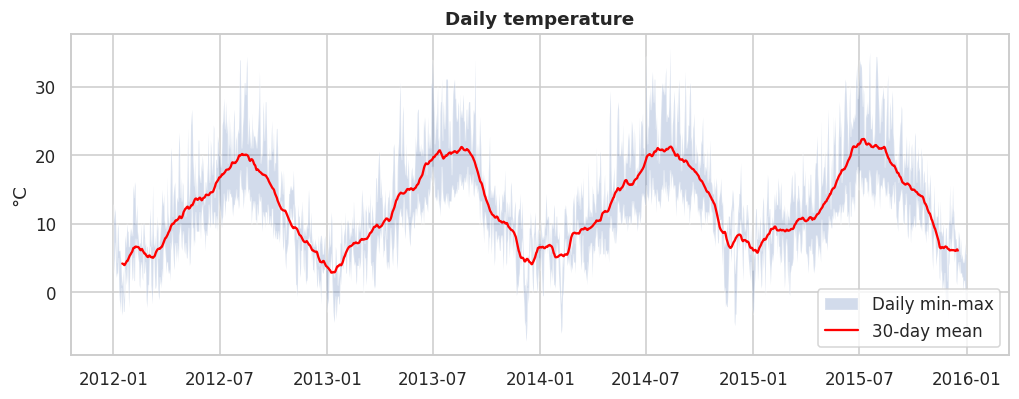

,tmax,tmin,tmean,precip,wet_days
Year,,,,,
2012,15.3,7.3,11.3,1226.0,148
2013,16.1,8.2,12.1,828.0,119
2014,17.0,8.7,12.8,1232.8,123
2015,17.4,8.8,13.1,1139.2,116


Trend: +0.58 °C per year (95% interval +/- 0.26), r = 0.54, p = 7.1e-05
Mean temperature differs by year (ANOVA): p = 1.1e-04
{2012: -1.04, 2013: -0.23, 2014: 0.49, 2015: 0.79}


In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(df.date, df.temp_min, df.temp_max, alpha=.25, label="Daily min-max")
ax.plot(df.date, df.temp_mean.rolling(30, center=True).mean(), color="red", label="30-day mean")
ax.set_ylabel("°C"); ax.set_title("Daily temperature"); ax.legend(); plt.show()

yr = df.groupby("Year").agg(tmax=("temp_max", "mean"), tmin=("temp_min", "mean"), tmean=("temp_mean", "mean"), precip=("precipitation", "sum"), wet_days=("wet", "sum")).round(1)
display(yr)

# anomalies vs each calendar month's 4-year mean (removes the seasonal cycle)
df["anom"] = df.temp_mean - df.groupby("Month").temp_mean.transform("mean")
ma = df.groupby(["Year", "Month"]).anom.mean().reset_index(); ma["t"] = np.arange(len(ma))
lr = stats.linregress(ma.t, ma.anom)
print("Trend: %+.2f °C per year (95%% interval +/- %.2f), r = %.2f, p = %.1e" % (lr.slope * 12, lr.stderr * 1.96 * 12, lr.rvalue, lr.pvalue))
print("Mean temperature differs by year (ANOVA): p = %.1e" % stats.f_oneway(*[g.temp_mean for _, g in df.groupby("Year")]).pvalue)
print(df.groupby("Year").anom.mean().round(2).to_dict())

## 4. Seasonal patterns

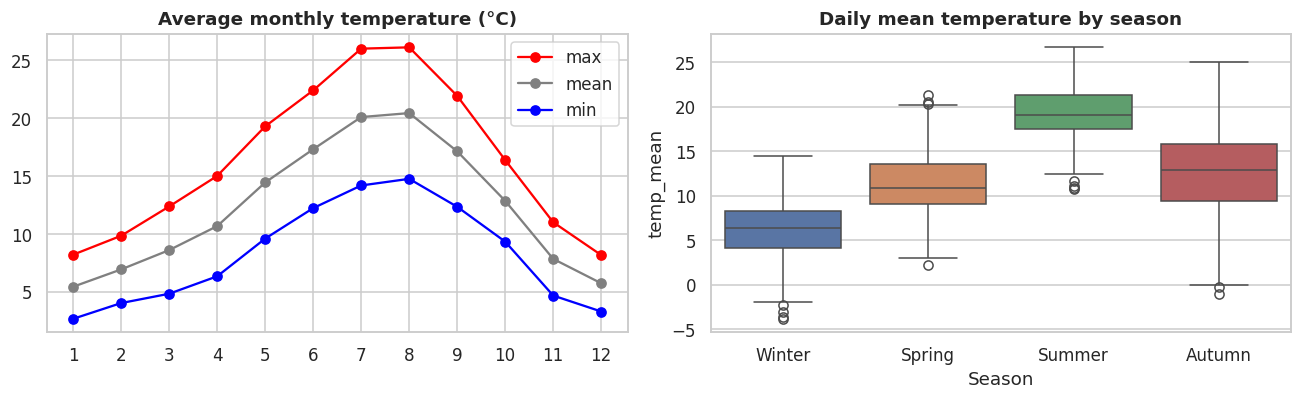

,tmean,swing,wind,wet_pct,rain,rain_share_%
Season,,,,,,
Winter,6.03,5.39,3.51,51.80,1510.7,34.1
Spring,11.26,8.62,3.41,37.50,1189.1,26.9
Summer,19.31,11.11,2.93,13.04,344.8,7.8
Autumn,12.63,7.64,3.13,36.54,1381.4,31.2


Season ANOVA (temperature): p = 2.1e-307
Weather type mix depends on season (chi-square): p = 1.3e-36


weather,drizzle,fog,rain,snow,sun
Season,,,,,
Winter,4.4,7.8,58.7,5.0,24.1
Spring,1.9,3.8,47.3,1.9,45.1
Summer,4.9,4.6,22.3,0.0,68.2
Autumn,3.3,11.5,47.5,0.3,37.4


In [5]:
mo = df.groupby("Month").agg(tmax=("temp_max", "mean"), tmin=("temp_min", "mean"), tmean=("temp_mean", "mean"))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(range(1, 13), mo.tmax, "o-", color="red", label="max"); axs[0].plot(range(1, 13), mo.tmean, "o-", color="grey", label="mean"); axs[0].plot(range(1, 13), mo.tmin, "o-", color="blue", label="min")
axs[0].set_xticks(range(1, 13)); axs[0].set_title("Average monthly temperature (°C)"); axs[0].legend()
sns.boxplot(data=df, x="Season", y="temp_mean", hue="Season", legend=False, ax=axs[1]); axs[1].set_title("Daily mean temperature by season")
plt.tight_layout(); plt.show()

se = df.groupby("Season", observed=True).agg(tmean=("temp_mean", "mean"), swing=("temp_range", "mean"), wind=("wind", "mean"), wet_pct=("wet", lambda s: s.mean() * 100), rain=("precipitation", "sum")).round(2)
se["rain_share_%"] = (se.rain / se.rain.sum() * 100).round(1); display(se)
print("Season ANOVA (temperature): p = %.1e" % stats.f_oneway(*[g.temp_mean for _, g in df.groupby("Season", observed=True)]).pvalue)
print("Weather type mix depends on season (chi-square): p = %.1e" % stats.chi2_contingency(pd.crosstab(df.Season, df.weather))[1])
pd.crosstab(df.Season, df.weather, normalize="index").mul(100).round(1)

## 5. Rainfall distribution

Wet days: 506 (34.6%) | completely dry days: 838 (57.4%)
Wet-day rain: median 5.3 mm, mean 8.6 mm, 95th percentile 27.4 mm, skewness 2.1
Heaviest 10% of wet days give 35% of total rain


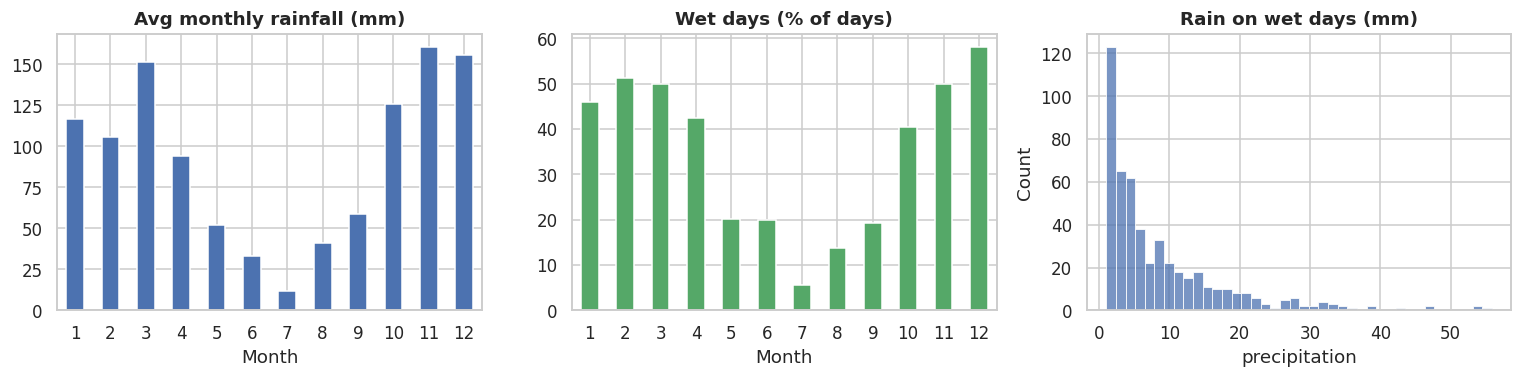

Rainfall by season (Kruskal-Wallis): p = 6.6e-30
Rainfall by year (Kruskal-Wallis): p = 0.039


In [6]:
w = df[df.wet]
print("Wet days: %d (%.1f%%) | completely dry days: %d (%.1f%%)" % (df.wet.sum(), df.wet.mean() * 100, (df.precipitation == 0).sum(), (df.precipitation == 0).mean() * 100))
print("Wet-day rain: median %.1f mm, mean %.1f mm, 95th percentile %.1f mm, skewness %.1f" % (w.precipitation.median(), w.precipitation.mean(), w.precipitation.quantile(.95), stats.skew(w.precipitation)))
k = int(np.ceil(.1 * len(w))); print("Heaviest 10%% of wet days give %.0f%% of total rain" % (w.precipitation.nlargest(k).sum() / w.precipitation.sum() * 100))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
(df.groupby("Month").precipitation.sum() / 4).plot.bar(ax=axs[0], rot=0); axs[0].set_title("Avg monthly rainfall (mm)")
(df.groupby("Month").wet.mean() * 100).plot.bar(ax=axs[1], rot=0, color="C2"); axs[1].set_title("Wet days (% of days)")
sns.histplot(w.precipitation, bins=40, ax=axs[2]); axs[2].set_title("Rain on wet days (mm)")
plt.tight_layout(); plt.show()
print("Rainfall by season (Kruskal-Wallis): p = %.1e" % stats.kruskal(*[g.precipitation for _, g in df.groupby("Season", observed=True)]).pvalue)
print("Rainfall by year (Kruskal-Wallis): p = %.3f" % stats.kruskal(*[g.precipitation for _, g in df.groupby("Year")]).pvalue)

## 6. Extreme weather events

Thresholds: hot >= 28.9 °C | cold <= 0.0 °C | heavy rain >= 27.4 mm | windy >= 6.0


,hot,cold,heavy_rain,windy
Year,,,,
2012,9,21,6,22
2013,19,30,5,18
2014,27,22,6,23
2015,30,15,11,17


Days >= 30 °C: 63 | freezing nights: 88
Longest dry spells (<1 mm) [(81, '2012-07-23', '2012-10-11'), (54, '2015-06-02', '2015-07-25'), (35, '2013-06-28', '2013-08-01')]
Longest wet spells [(15, '2014-02-10', '2014-02-24'), (14, '2012-03-09', '2012-03-22'), (13, '2015-11-07', '2015-11-19')]
Heat waves (3+ days hot) [(8, '2015-06-29', '2015-07-06'), (8, '2014-07-28', '2014-08-04'), (6, '2012-08-12', '2012-08-17')]


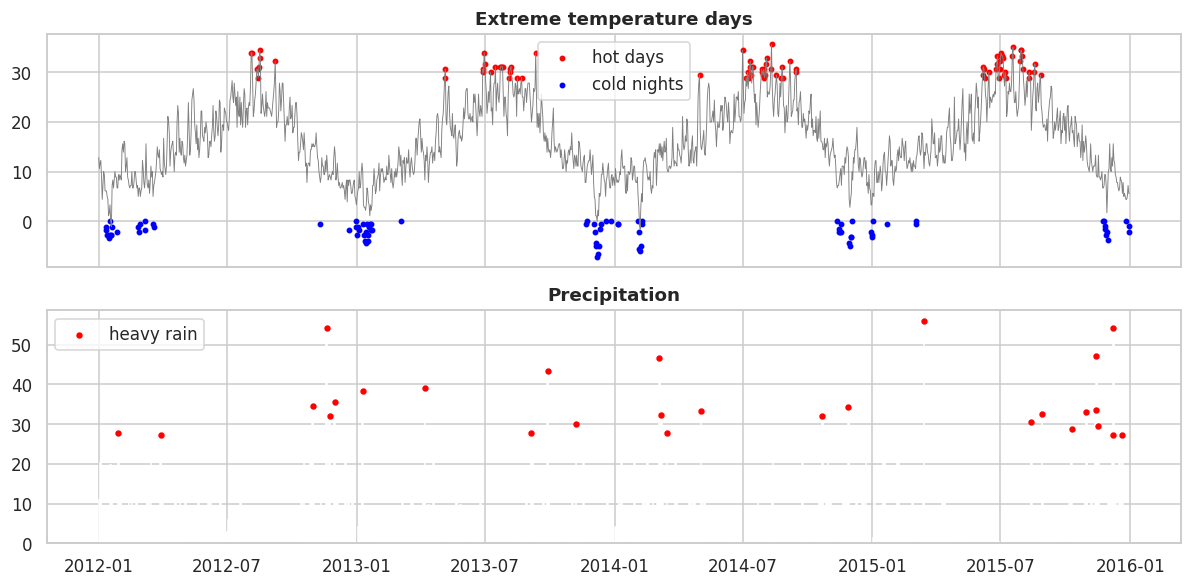

In [7]:
p95_hot, p05_cold = df.temp_max.quantile(.95), df.temp_min.quantile(.05)
p95_rain, p95_wind = w.precipitation.quantile(.95), df.wind.quantile(.95)
print("Thresholds: hot >= %.1f °C | cold <= %.1f °C | heavy rain >= %.1f mm | windy >= %.1f" % (p95_hot, p05_cold, p95_rain, p95_wind))
ex = pd.DataFrame({"Year": df.Year, "hot": df.temp_max >= p95_hot, "cold": df.temp_min <= p05_cold, "heavy_rain": df.precipitation >= p95_rain, "windy": df.wind >= p95_wind})
display(ex.groupby("Year").sum())
print("Days >= 30 °C:", int((df.temp_max >= 30).sum()), "| freezing nights:", int((df.temp_min <= 0).sum()))

def streaks(b):
    out, cur = [], 0
    for i, v in enumerate(b):
        if v: cur += 1
        else:
            if cur: out.append((cur, i - cur, i - 1))
            cur = 0
    if cur: out.append((cur, len(b) - cur, len(b) - 1))
    return out
d = df.date.dt.date.values
for name, mask in [("Longest dry spells (<1 mm)", ~df.wet.values), ("Longest wet spells", df.wet.values), ("Heat waves (3+ days hot)", (df.temp_max >= p95_hot).values)]:
    res = [s for s in sorted(streaks(mask), reverse=True) if name.startswith("Heat") is False or s[0] >= 3][:3]
    print(name, [(n, str(d[a]), str(d[b])) for n, a, b in res])

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axs[0].plot(df.date, df.temp_max, lw=.6, color="grey"); h = df[df.temp_max >= p95_hot]; axs[0].scatter(h.date, h.temp_max, s=8, color="red", label="hot days")
c = df[df.temp_min <= p05_cold]; axs[0].scatter(c.date, c.temp_min, s=8, color="blue", label="cold nights"); axs[0].legend(); axs[0].set_title("Extreme temperature days")
axs[1].bar(df.date, df.precipitation, width=1); hv = df[df.precipitation >= p95_rain]; axs[1].scatter(hv.date, hv.precipitation, s=10, color="red", label="heavy rain"); axs[1].legend(); axs[1].set_title("Precipitation")
plt.tight_layout(); plt.show()

## 7. Relationships

Max vs min temperature: r = 0.88
Rain vs daily temperature range: Spearman rho = -0.58
Rain vs wind: Spearman rho = 0.33


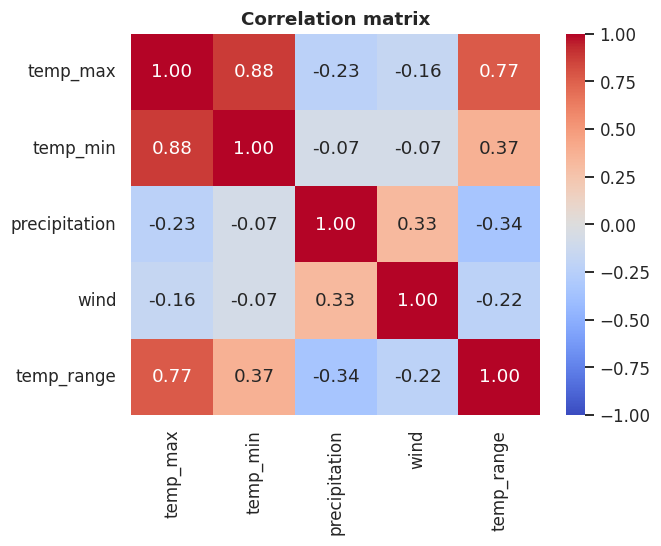

In [8]:
print("Max vs min temperature: r = %.2f" % stats.pearsonr(df.temp_max, df.temp_min)[0])
print("Rain vs daily temperature range: Spearman rho = %.2f" % stats.spearmanr(df.precipitation, df.temp_range)[0])
print("Rain vs wind: Spearman rho = %.2f" % stats.spearmanr(df.precipitation, df.wind)[0])
plt.figure(figsize=(6, 4.5)); sns.heatmap(df[["temp_max", "temp_min", "precipitation", "wind", "temp_range"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.show()

## 8. Findings and recommendations

| Finding | Evidence |
|---|---|
| Strong seasonality | summer mean 19.3 °C vs winter 6.0 °C; summer gets 8% of rain, winter 34% |
| Warming across 2012-2015 | +0.58 °C per year in monthly anomalies (window only, not a climate trend) |
| Rain is concentrated | heaviest 10% of wet days give about 35% of rain; median wet day 5.3 mm vs mean 8.6 mm |
| More hot days each year | 9, 19, 27, 30 |
| Longest dry spell | 81 days (Jul-Oct 2012) |

**Recommendations:** (1) schedule outdoor work Jun-Sep; (2) size drainage for single-day extremes; (3) heat-readiness plan for Jul-Aug; (4) winter cold and wind preparation; (5) plan energy and staffing by season; (6) percentile-based alert thresholds; (7) plan water use for 6+ week dry spells; (8) extend the record to 10+ years and fix weather labels before trend claims.

**Limitations:** single location, four years, inferred units, weather labels inconsistent with measurements, daily data autocorrelated so p-values overstate certainty.